# 8.3 Model Evaluation Statistics

**Goal:** compute classification metrics and distinguish ranking, threshold decisions, calibration, and uncertainty.

**Prerequisites:** Modules 0–4 and earlier notebooks in this module; advanced notebooks also build on earlier modules 5–8. Read the section assumptions before using a method.

**Runtime:** Python 3.10+ with NumPy, SciPy, and Matplotlib. Install in your chosen environment with `python3 -m pip install numpy scipy matplotlib`, then open in JupyterLab or VS Code with a Python kernel. Use **Restart Kernel and Run All**. Each notebook is self-contained, includes saved outputs, uses synthetic data and a fixed local random seed, and needs no downloads. Numerical simulations illustrate results; they do not prove them or validate real-world assumptions.

## Module navigation

1. [Data Preprocessing](1_Data-Preprocessing.ipynb)
2. [Feature Engineering](2_Feature-Engineering.ipynb)
3. [Model Evaluation Statistics](3_Model-Evaluation-Statistics.ipynb)
4. [Statistical Learning Concepts](4_Statistical-Learning-Concepts.ipynb)
5. [Advanced ML Statistics](5_Advanced-ML-Statistics.ipynb)

## Learning route

Read each definition and assumption, work through its calculation, run the code, then attempt the practice before viewing the solutions. Distinguish descriptive association, causal inference, and predictive evaluation throughout.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats, optimize, special, linalg
rng = np.random.default_rng(2026)
plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 12, "font.size": 10})

## 1. Confusion Matrix; Accuracy, Precision, Recall, Specificity, and F1-score

At a specified positive class and threshold, counts are TP,FP,TN,FN. Accuracy=(TP+TN)/N; precision=TP/(TP+FP); recall/sensitivity=TP/(TP+FN); specificity=TN/(TN+FP). F1=2TP/(2TP+FP+FN) is a harmonic balance of precision and recall, not a proper probability score. State a policy for zero denominators rather than silently imply an undefined quantity equals zero.

These metrics depend on thresholds and prevalence. A 99%-accurate always-negative model in a 1%-positive population has zero recall. Precision can change when prevalence changes even with unchanged sensitivity and specificity. Micro, macro, and weighted multiclass averages answer different aggregation questions.

**Worked example:** compute metrics from aligned labels and scores at threshold .5, with 1 denoting the positive event.

In [2]:
y=np.array([0,0,1,0,1,1,0,1,0,1]);scores=np.array([.05,.3,.7,.6,.8,.4,.2,.9,.1,.55])
pred=scores>=.5
TP=np.sum(pred&(y==1));FP=np.sum(pred&(y==0));TN=np.sum(~pred&(y==0));FN=np.sum(~pred&(y==1))
print("Confusion [[TN,FP],[FN,TP]]:",np.array([[TN,FP],[FN,TP]]))
print("Accuracy:",(TP+TN)/len(y),"precision:",TP/(TP+FP),"recall:",TP/(TP+FN),"specificity:",TN/(TN+FP),"F1:",2*TP/(2*TP+FP+FN))

Confusion [[TN,FP],[FN,TP]]: [[4 1]
 [1 4]]
Accuracy: 0.8 precision: 0.8 recall: 0.8 specificity: 0.8 F1: 0.8


## 2. ROC Curve, AUC, and Precision-Recall Curve

ROC plots true-positive rate against false-positive rate across score thresholds. ROC AUC measures pairwise ranking: probability a randomly chosen positive scores above a negative plus half tie probability. Both classes must be present. It does not select a threshold or guarantee calibration, and it can conceal poor precision in rare-event settings.

A precision-recall curve plots precision against recall and depends on positive prevalence. Average precision summarizes recall increments weighted by precision; it is not generally identical to trapezoidal PR AUC. State the interpolation convention. Curves from small datasets can be unstable; compare models on matched cases and an appropriate uncertainty design.

ROC AUC: 0.92 step average precision: 0.9266666666666666


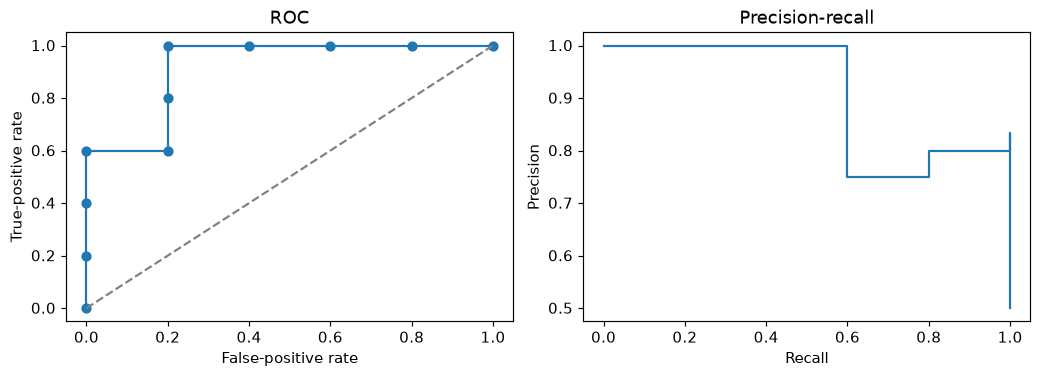

In [3]:
thresholds=np.r_[np.inf,np.unique(scores)[::-1]]
tpr=[];fpr=[];precision=[]
for threshold in thresholds:
    predicted=scores>=threshold;tp=np.sum(predicted&(y==1));fp=np.sum(predicted&(y==0))
    tpr.append(tp/np.sum(y==1));fpr.append(fp/np.sum(y==0));precision.append(tp/(tp+fp) if tp+fp else 1.)
from scipy.integrate import trapezoid
auc=trapezoid(tpr,fpr)
average_precision=np.sum(np.diff(tpr)*np.array(precision)[1:])
print("ROC AUC:",auc,"step average precision:",average_precision)
fig,axes=plt.subplots(1,2,figsize=(10,3.7))
axes[0].plot(fpr,tpr,marker="o");axes[0].plot([0,1],[0,1],"--",color="gray")
axes[0].set(title="ROC",xlabel="False-positive rate",ylabel="True-positive rate")
axes[1].step(tpr,precision,where="post");axes[1].set(title="Precision-recall",xlabel="Recall",ylabel="Precision")
fig.tight_layout();plt.show()

## 3. Log Loss, Brier Score, and Calibration

Binary log loss is $-N^{-1}\sum[y\log p+(1-y)\log(1-p)]$; Brier score is $N^{-1}\sum(p-y)²$. Both are proper scoring rules for probabilistic predictions under the appropriate target distribution. Log loss heavily penalizes confident wrong predictions. Numerical clipping prevents log(0) in code but does not justify replacing genuinely certain invalid predictions with calibrated estimates.

**Calibration** means observed event frequency matches stated probabilities in the relevant conditional/aggregate sense. Reliability diagrams compare binned mean predictions and observed rates; bin choice and sample size matter, and a diagonal-looking tiny plot proves little. Ranking and calibration differ: a monotone score transformation can preserve AUC while changing probability quality.

Evaluate calibration on data not used to fit its correction. Deployment population changes can break earlier calibration.

In [4]:
eps=1e-12;p=np.clip(scores,eps,1-eps)
logloss=-np.mean(y*np.log(p)+(1-y)*np.log1p(-p));brier=np.mean((scores-y)**2)
print("Log loss:",logloss,"Brier:",brier)
for lo,hi in [(0,.4),(.4,.7),(.7,1.000001)]:
    mask=(scores>=lo)&(scores<hi)
    print("Bin:",lo,hi,"n:",mask.sum(),"mean p:",scores[mask].mean(),"event rate:",y[mask].mean())

Log loss: 0.3852069780713018 Brier: 0.12049999999999998
Bin: 0 0.4 n: 4 mean p: 0.1625 event rate: 0.0
Bin: 0.4 0.7 n: 3 mean p: 0.5166666666666667 event rate: 0.6666666666666666
Bin: 0.7 1.000001 n: 3 mean p: 0.7999999999999999 event rate: 1.0


## 4. Confidence Intervals for Metrics

For fixed-model accuracy on IID common-probability cases, use a suitable binomial interval such as Wilson or exact inversion. For precision, the denominator is predicted positives and conditioning/design matters. AUC, F1, and paired metric differences may need analytic or resampling methods matched to the units. Rare classes, small samples, repeated users, and model retraining complicate uncertainty.

**Example:** an exact binomial interval for this ten-case accuracy illustrates its wide uncertainty. It is not an interval for future performance under arbitrary distribution shift or a fully retrained pipeline. Use paired bootstrap for fixed models scored on the same independent cases, and group/bootstrap whole users when needed.

In [5]:
correct=int(np.sum(pred==y));ci=stats.binomtest(correct,len(y)).proportion_ci(method="exact")
print("Accuracy correct/total:",correct,len(y),"exact binomial interval:",ci)
# Independent pairwise ranking identity for the ROC AUC calculation.
positive=scores[y==1];negative=scores[y==0]
pair_auc=np.mean(positive[:,None]>negative[None,:])+.5*np.mean(positive[:,None]==negative[None,:])
assert np.isclose(auc,pair_auc)

Accuracy correct/total: 8 10 exact binomial interval: ConfidenceInterval(low=np.float64(0.4439045376923585), high=np.float64(0.9747892736731666))


## AI/ML application and interpretation

Choose metrics from operational costs and deployment prevalence. Report thresholds, class definitions, denominators, averaging, uncertainty, and calibration separately. A single best metric chosen after testing many alternatives is a selection process; reserve independent evaluation and inspect important user groups.

## Practice

1. Which denominator distinguishes precision from recall?
2. Can a model have high AUC but poor probability calibration?
3. Why is PR analysis useful for a rare positive class?
4. Is F1 a proper score for probability estimates?
5. Why preserve pairing when comparing two models on the same cases?

## Solutions

1. Precision conditions on predicted positives; recall conditions on actual positives.
2. Yes. Good ranking does not fix probability magnitudes.
3. It directly displays precision tradeoffs under the observed prevalence, which ROC can obscure.
4. No. It summarizes thresholded decisions and ignores much of the probabilistic information.
5. Per-case outcomes are correlated across models; paired analysis uses the right difference structure and uncertainty.

**Readiness check:** identify the estimand, independent unit, assumptions, uncertainty source, and an important failure mode before using these methods.

**Next:** [Continue studying](4_Statistical-Learning-Concepts.ipynb).